# Project Report

# 1. Project Information

## Overview

| Item         | Description |
| ------------ | ----------- |
| Project Name | Prediksi Penyelesaian Kursus |
| Author       | Marlin Purnama Sari |
| Organization | Belum dicantumkan |
| Date Started | Belum dicantumkan |
| Last Updated | Belum dicantumkan |
| Version      | 1.0 |
| Dataset      | 1.000 data pengguna, 10 fitur, target `completed_course_flag` |

---

## Objective

Memprediksi apakah pengguna menyelesaikan kursus (`completed_course_flag`) berdasarkan demografi, metode pendaftaran, perangkat, dan aktivitas belajar. Tujuan bisnisnya adalah membantu mengidentifikasi pengguna yang berpotensi tidak menyelesaikan kursus agar dapat diberikan dukungan yang sesuai.

---

## Success Criteria

Target minimum belum ditentukan. Hasil yang tercatat pada data uji 80:20 adalah:

| Metric    | Hasil aktual |
| --------- | ------------ |
| Accuracy  | 0,955 |
| Precision | 0,957 |
| Recall    | 0,966 |
| F1-score  | 0,961 |
| RMSE      | Tidak digunakan untuk klasifikasi ini |
| MAE       | Tidak digunakan untuk klasifikasi ini |
| WER       | Tidak relevan |
| CER       | Tidak relevan |

---

# 2. Problem Statement

## Business Problem

Belum diketahui secara dini pengguna mana yang berisiko tidak menyelesaikan kursus. Model klasifikasi digunakan untuk memprediksi penyelesaian kursus dari data aktivitas dan profil pengguna.

---

## Expected Outcome

Menghasilkan model klasifikasi yang dapat memprediksi penyelesaian kursus serta laporan evaluasi untuk membandingkan pembagian data dan konfigurasi model. Hasil prediksi dapat menjadi masukan untuk merancang intervensi bagi pengguna.

---

# Experiment 1: Split Data

## Objective

Mengukur performa model dengan membandingkan split data 80:20 dan 90:10.

## Problem

Distribusi target tidak sepenuhnya seimbang. Perbandingan split perlu dievaluasi dengan pembagian stratifikasi agar proporsi kelas tetap terjaga.

## Hypothesis

Perbandingan split data yang berbeda dapat memengaruhi performa model.

---

## Scenario Configuration

### Data Version

- Dataset: 1.000 baris; target `completed_course_flag`
- Feature Engineering: StandardScaler untuk fitur numerik dan OneHotEncoder untuk fitur kategorikal
- Train/Test Split: 80:20 tercatat; hasil split 90:10 belum tersedia
- Random Seed: 42
- Evaluation Metrics:
  - Accuracy
  - Precision
  - Recall
  - F1-score

---

## Model Configuration

| EXP ID | Model | Important Parameters | Split |
| ------ | ----- | -------------------- | ----- |
| EXP-1A | RandomForestClassifier | `min_samples_leaf=5` | 80:20 |
| EXP-1B | RandomForestClassifier | Belum tercatat | 90:10 |

---

## Experiment Result

Metrik untuk EXP-1A dihitung dari confusion matrix `[[79, 5], [4, 112]]`. Model yang menghasilkan confusion matrix tersebut belum teridentifikasi secara pasti di notebook.

| EXP ID | Model | Accuracy | Precision | Recall | F1 - Score |
| ------ | ----- | -------- | --------- | ------ | ---------- |
| EXP-1A | Random Forest (detail run belum terkonfirmasi) | 0,955 | 0,957 | 0,966 | 0,961 |
| EXP-1B | Random Forest | Belum tersedia | Belum tersedia | Belum tersedia | Belum tersedia |

## Conclusion

Hasil split 80:20 menunjukkan performa tinggi pada data uji. Perbandingan dengan split 90:10 belum dapat disimpulkan karena hasil evaluasinya belum tersedia.

## Decision

- Decision: Gunakan split 80:20 sebagai baseline sementara; pastikan model yang terkait dengan confusion matrix tercatat.
- Next Scenario: Hyperparameter Tuning

# Experiment 2: Hyperparameter Tuning

## Objective

Mengukur performa model dari eksperimen sebelumnya menggunakan kombinasi parameter utama.

## Problem

Parameter Random Forest dapat memengaruhi performa model dan perlu dievaluasi secara sistematis.

## Hypothesis

Kombinasi parameter yang berbeda dapat menghasilkan performa model yang berbeda.

---

## Scenario Configuration

### Data Version

- Dataset: 1.000 baris; target `completed_course_flag`
- Feature Engineering: StandardScaler untuk fitur numerik dan OneHotEncoder untuk fitur kategorikal
- Train/Test Split: 80:20 tercatat
- Random Seed: 42 untuk StratifiedKFold
- Evaluation Metrics:
  - Accuracy
  - Precision
  - Recall
  - F1-score
- Cross-validation: StratifiedKFold, 5 fold, `shuffle=True`

---

## Model Configuration

| EXP ID | Model | Important Parameters | Split |
| ------ | ----- | -------------------- | ----- |
| EXP-2A | RandomForestClassifier | `n_estimators`: 50, 100, 150; `max_depth`: 5, 10, None; `min_samples_leaf`: 5, 7, None | 80:20 |
| EXP-2B | RandomForestClassifier | Model terbaik yang tercatat: `min_samples_leaf=5`; parameter lainnya belum terkonfirmasi | 80:20 |

---

## Experiment Result

| EXP ID | Model | Accuracy | Precision | Recall | F1 - Score |
| ------ | ----- | -------- | --------- | ------ | ---------- |
| EXP-2A | GridSearchCV RandomForestClassifier | Belum tersedia | Belum tersedia | Belum tersedia | Belum tersedia |
| EXP-2B | RandomForestClassifier (`min_samples_leaf=5`) | Belum tersedia secara pasti | Belum tersedia secara pasti | Belum tersedia secara pasti | Belum tersedia secara pasti |

## Conclusion

Grid search menggunakan 5-fold StratifiedKFold dan scoring accuracy. Notebook mencatat model `RandomForestClassifier(min_samples_leaf=5)`, tetapi `best_params_`, skor validasi terbaik, dan metrik uji yang dapat dipastikan untuk eksperimen ini belum tersedia.

## Decision

- Decision: Catat `best_params_` dan evaluasi model hasil tuning pada data uji sebelum menetapkannya sebagai model terbaik.
- Next Scenario: Evaluasi dan dokumentasi model terbaik.


## Associate Data Scientist 

In [2]:
import pandas as pd

df = pd.read_csv('dataset_machine_learning.csv')

In [3]:
df.info
df

,user_id,age,gender,signup_method,device_type,days_active,courses_enrolled,courses_completed,quizzes_attempted,average_score,time_spent_minutes,completed_course_flag
0,U00001,56.0,Male,Google,Desktop,32,3,5,9,72.00,9115,1
1,U00002,46.0,Other,Google,Tablet,109,6,9,24,64.34,10863,1
2,U00003,32.0,Female,Facebook,Mobile,51,9,1,1,50.15,4385,0
3,U00004,NaN,Male,Facebook,Mobile,113,1,7,8,98.65,8331,1
4,U00005,25.0,Female,Google,Mobile,85,1,9,10,NaN,10521,1
...,...,...,...,...,...,...,...,...,...,...,...,...
995,U00996,50.0,NaN,NaN,Tablet,61,5,8,6,82.58,11594,1
996,U00997,21.0,Male,Google,Tablet,119,6,4,17,40.44,12272,0
997,U00998,39.0,Female,NaN,Tablet,4,8,7,20,71.09,8494,1
998,U00999,19.0,Female,NaN,Desktop,88,4,8,21,NaN,8260,1


### 1. Praprocessing

In [4]:
missing = df.isnull().sum()
missing[missing > 0]

age               12
gender           235
signup_method    247
average_score    100
dtype: int64

In [5]:
# Handling missing value
# median
for col in ['age', 'average_score']:
    df[col] = df[col].fillna(df[col].median())

# modus
for col in ['gender', 'signup_method']:
    df[col] = df[col].fillna(df[col].mode()[0])

df.isnull().sum()

user_id                  0
age                      0
gender                   0
signup_method            0
device_type              0
days_active              0
courses_enrolled         0
courses_completed        0
quizzes_attempted        0
average_score            0
time_spent_minutes       0
completed_course_flag    0
dtype: int64

In [6]:
# cek/handling duplicate
df.duplicated().sum()


0

In [7]:
# cek outliers

numeric_cols = df.select_dtypes(include='number').columns.drop('completed_course_flag')

outlier_counts = {}

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_counts[col] = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()

pd.Series(outlier_counts, name='outlier_count')

age                   0
days_active           0
courses_enrolled      0
courses_completed     0
quizzes_attempted     0
average_score         0
time_spent_minutes    0
Name: outlier_count, dtype: int64

In [15]:
X= df

X

,user_id,age,gender,signup_method,device_type,days_active,courses_enrolled,courses_completed,quizzes_attempted,average_score,time_spent_minutes,completed_course_flag
0,U00001,56.0,Male,Google,Desktop,32,3,5,9,72.00,9115,1
1,U00002,46.0,Other,Google,Tablet,109,6,9,24,64.34,10863,1
2,U00003,32.0,Female,Facebook,Mobile,51,9,1,1,50.15,4385,0
3,U00004,40.0,Male,Facebook,Mobile,113,1,7,8,98.65,8331,1
4,U00005,25.0,Female,Google,Mobile,85,1,9,10,69.12,10521,1
...,...,...,...,...,...,...,...,...,...,...,...,...
995,U00996,50.0,Male,Google,Tablet,61,5,8,6,82.58,11594,1
996,U00997,21.0,Male,Google,Tablet,119,6,4,17,40.44,12272,0
997,U00998,39.0,Female,Google,Tablet,4,8,7,20,71.09,8494,1
998,U00999,19.0,Female,Google,Desktop,88,4,8,21,69.12,8260,1


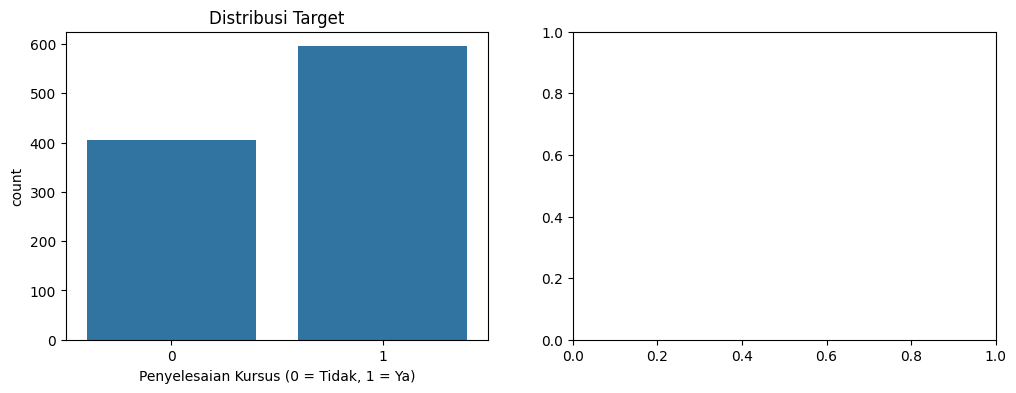

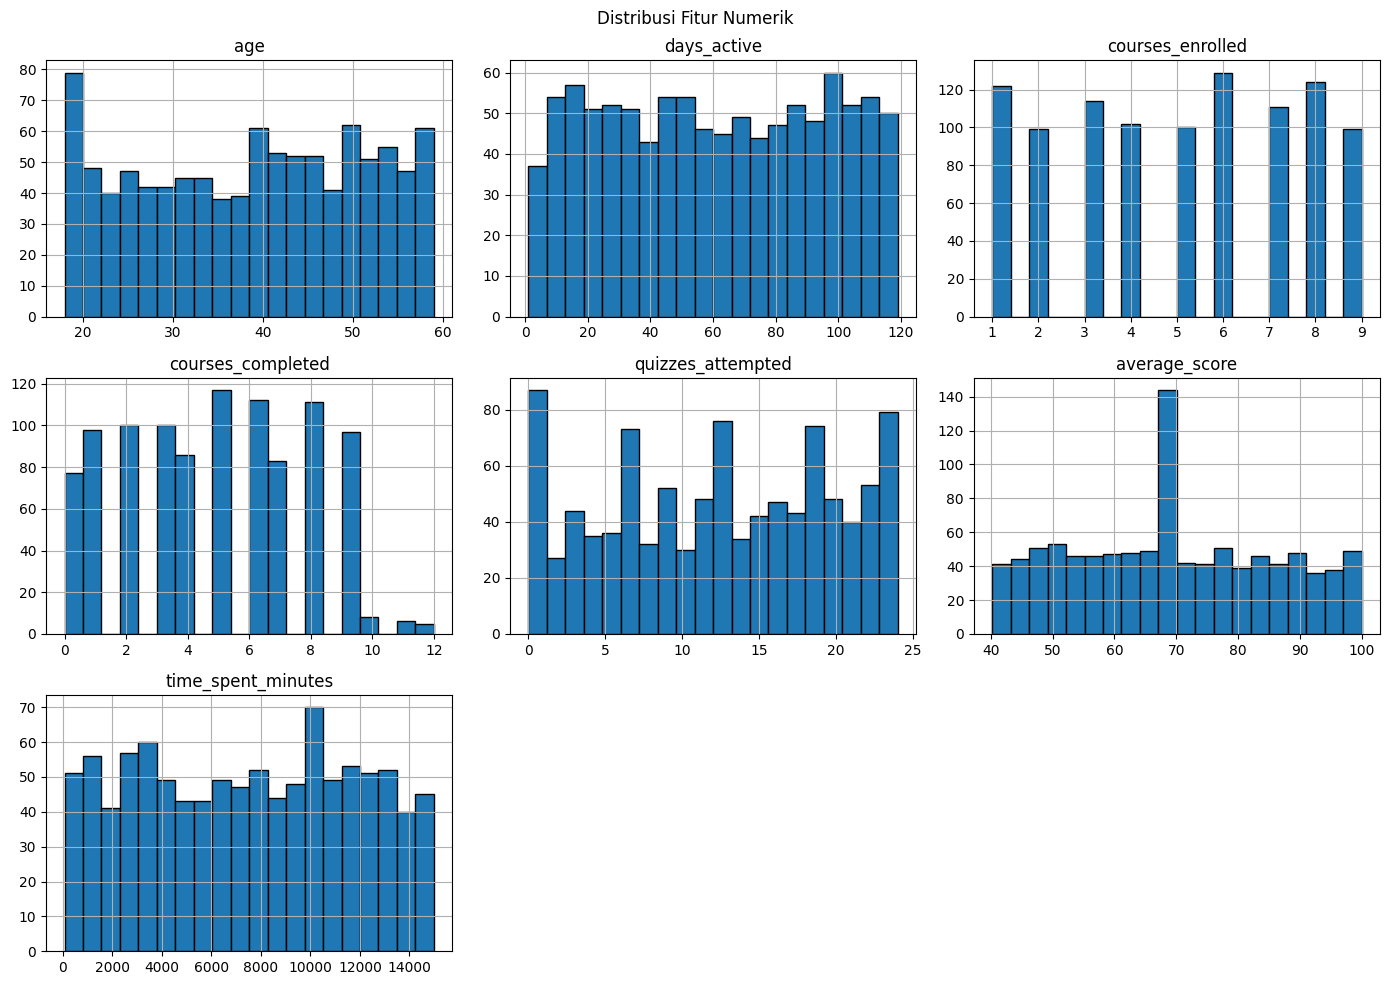

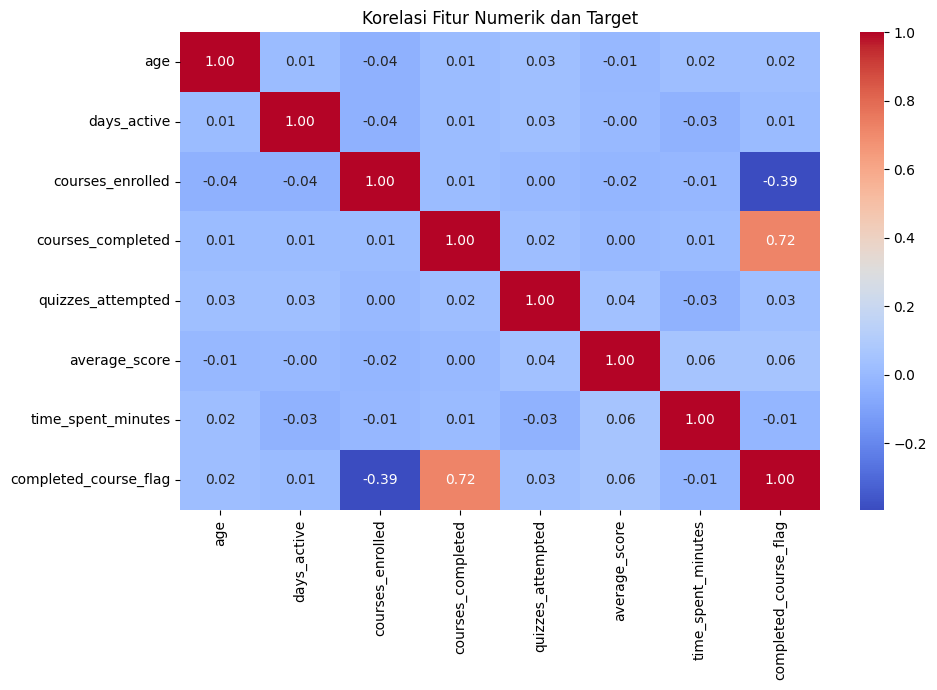

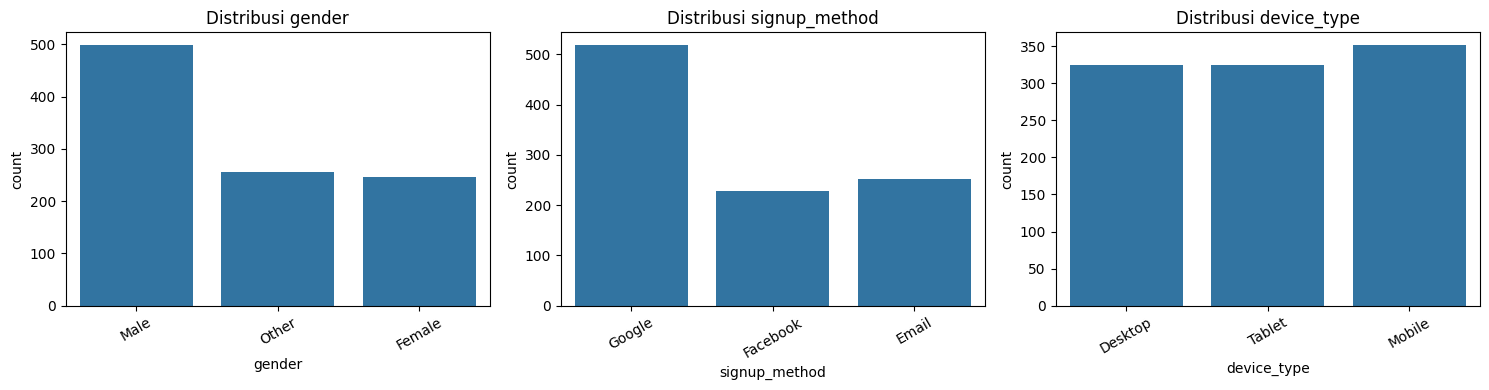

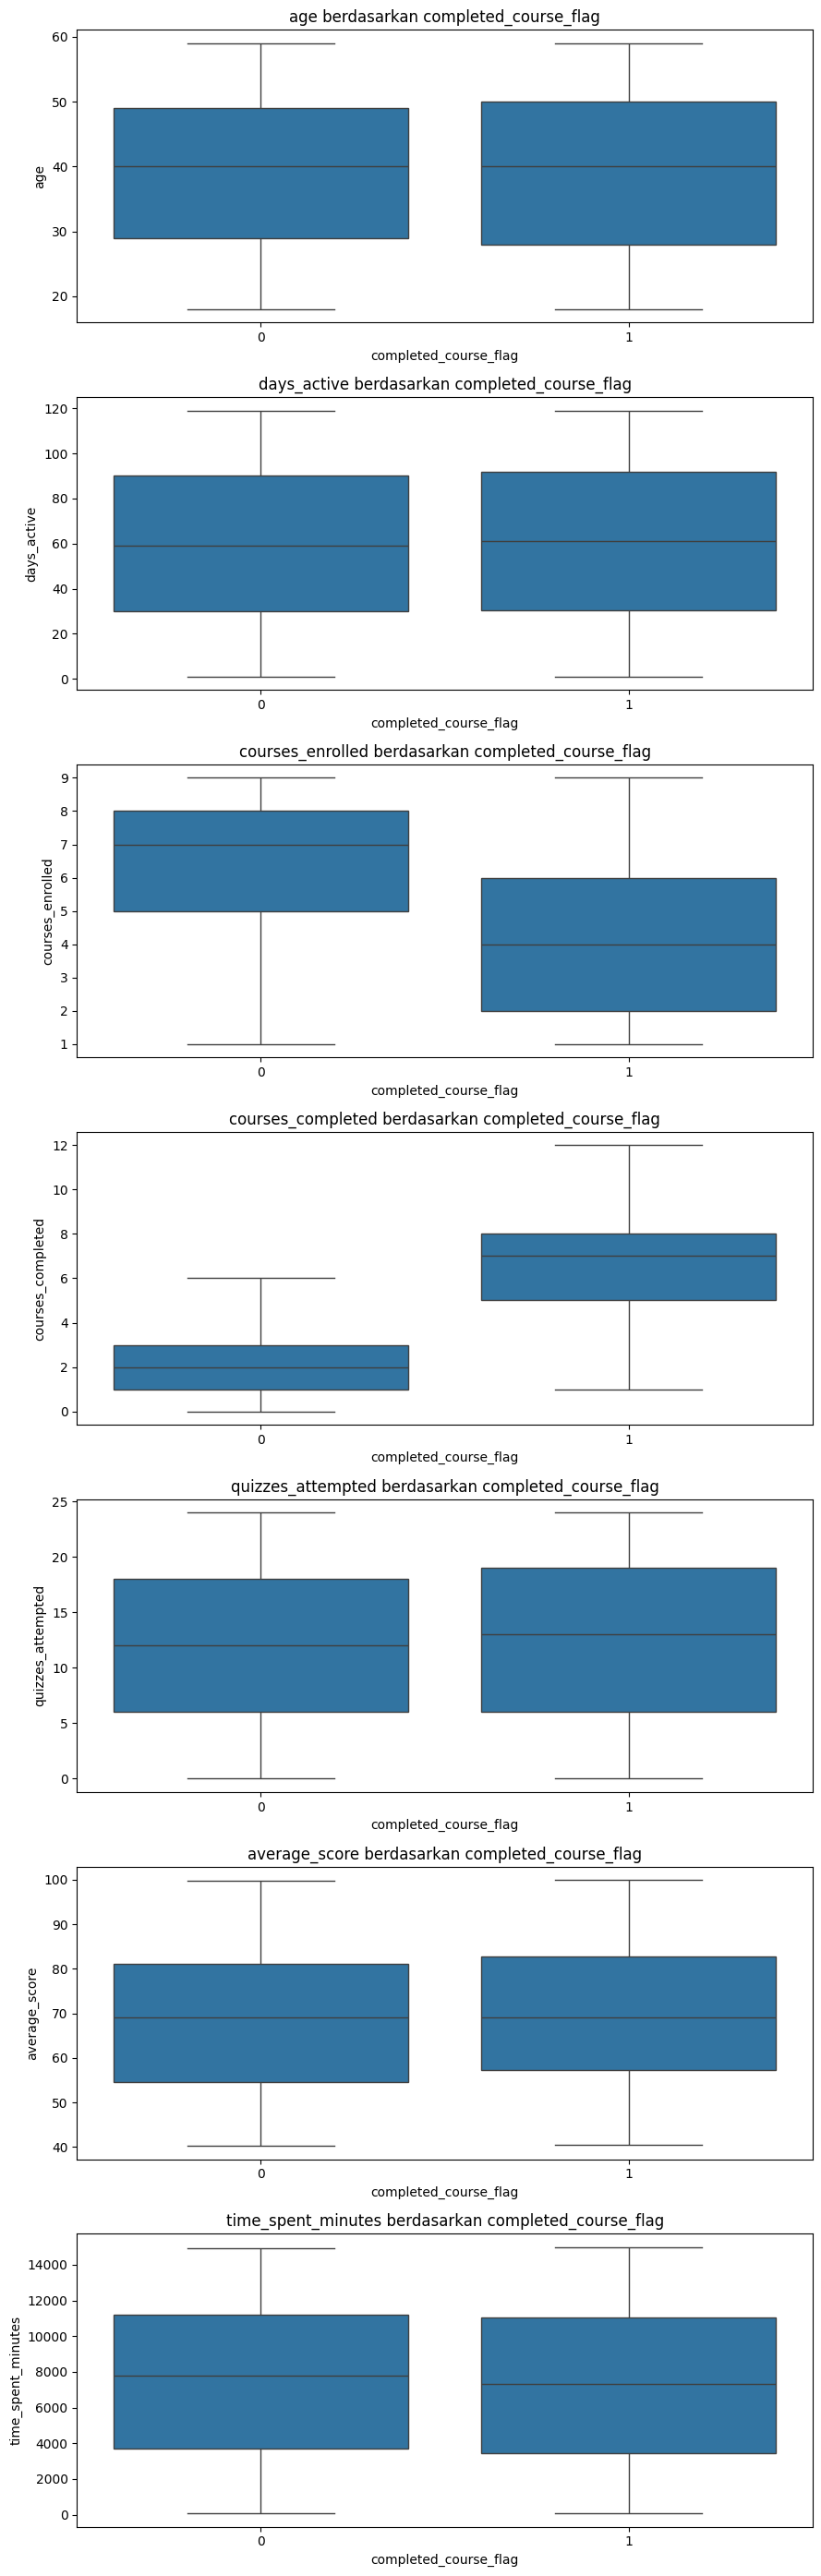

In [90]:
import seaborn as sns

import matplotlib.pyplot as plt

target = "completed_course_flag"
numeric_eda = df.select_dtypes(include="number").columns.drop(target, errors="ignore")
categorical_eda = df.select_dtypes(include="object").columns.drop("user_id", errors="ignore")

# Distribusi target
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=target, ax=axes[0])
axes[0].set_title("Distribusi Target")
axes[0].set_xlabel("Penyelesaian Kursus (0 = Tidak, 1 = Ya)")

# Distribusi fitur numerik
df[numeric_eda].hist(ax=None, bins=20, figsize=(14, 10), edgecolor="black")
plt.suptitle("Distribusi Fitur Numerik")
plt.tight_layout()
plt.show()

# Korelasi fitur numerik
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_eda.tolist() + [target]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Korelasi Fitur Numerik dan Target")
plt.tight_layout()
plt.show()

# Distribusi fitur kategorikal
fig, axes = plt.subplots(1, len(categorical_eda), figsize=(15, 4))
for ax, col in zip(axes, categorical_eda):
    sns.countplot(data=df, x=col, ax=ax)
    ax.set_title(f"Distribusi {col}")
    ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# Fitur numerik berdasarkan target
fig, axes = plt.subplots(len(numeric_eda), 1, figsize=(9, 4 * len(numeric_eda)))
for ax, col in zip(axes, numeric_eda):
    sns.boxplot(data=df, x=target, y=col, ax=ax)
    ax.set_title(f"{col} berdasarkan {target}")

plt.tight_layout()
plt.show()

##  Machine Learning

### 2. Feature Engineering

In [44]:
# Feature Selection
target = "completed_course_flag"
features = [col for col in df.columns if col not in [target, "user_id"]]

X = df[features]
y = df[target]


In [45]:
# Cek type column
X.dtypes


age                   float64
gender                 object
signup_method          object
device_type            object
days_active             int64
courses_enrolled        int64
courses_completed       int64
quizzes_attempted       int64
average_score         float64
time_spent_minutes      int64
dtype: object

In [46]:
# Pilih column sesuai type column
numeric = ['age','days_active','courses_enrolled','courses_completed','quizzes_attempted','average_score','time_spent_minutes']

categorical = ['gender','signup_method','device_type']

In [95]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Tahapan Preprocessing
ct = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric), # encoding numeric menjadi standard scaler
    ('cat', OneHotEncoder(), categorical) # encoding categorical menjadi onehotencode
])

In [1]:
ct

NameError: name 'ct' is not defined

In [48]:
# split to train and test

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=42)

In [ ]:
#  fitting
X_train_processed = ct.fit_transform(X_train)
X_test_processed = ct.transform(X_test)

In [50]:
from sklearn.ensemble import RandomForestClassifier

rfc = RandomForestClassifier()

rfc.fit(X_train_processed, y_train)

RandomForestClassifier()

In [56]:
# Predict
rfc_pred = rfc.predict(X_test_processed)

              precision    recall  f1-score   support

           0       0.98      0.96      0.97        84
           1       0.97      0.98      0.98       116

    accuracy                           0.97       200
   macro avg       0.98      0.97      0.97       200
weighted avg       0.98      0.97      0.97       200

[[ 81   3]
 [  2 114]]
ROC-AUC: 0.9978961412151067


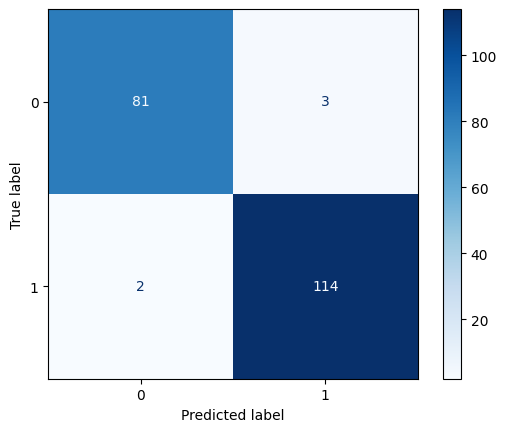

In [ ]:
# Evaluation

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

print(classification_report(y_test, rfc_pred))
print(confusion_matrix(y_test, rfc_pred))
positive_class_index = list(rfc.classes_).index(1)
y_score = rfc.predict_proba(X_test_processed)[:, positive_class_index]
print("ROC-AUC:", roc_auc_score(y_test, y_score))

cm = confusion_matrix(y_test, rfc_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=rfc.classes_)
disp.plot(cmap="Blues", values_format="d")

### Tuning

In [62]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [93]:
rfc_param = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, None],
    'min_samples_leaf': [5, 7, None]
}

In [94]:
# gridsearchCV
from sklearn.model_selection import GridSearchCV

rfc2 = RandomForestClassifier()

rfc2_cv = GridSearchCV(estimator=rfc2, param_grid=rfc_param, cv=cv, scoring='accuracy')

In [65]:
rfc2_cv.fit(X_train_processed, y_train)

d:\DEVELOPMENTS\BELAJAR\dsml\.venv\Lib\site-packages\sklearn\model_selection\_validation.py:547: FitFailedWarning: 
45 fits failed out of a total of 135.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
45 fits failed with the following error:
Traceback (most recent call last):
  File "d:\DEVELOPMENTS\BELAJAR\dsml\.venv\Lib\site-packages\sklearn\model_selection\_validation.py", line 895, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "d:\DEVELOPMENTS\BELAJAR\dsml\.venv\Lib\site-packages\sklearn\base.py", line 1467, in wrapper
    estimator._validate_params()
  File "d:\DEVELOPMENTS\BELAJAR\dsml\.venv\Lib\site-packages\sklearn\base.py", line 666, in _validate_params
    validate_parameter_constraints(
  File "d:

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(),
             param_grid={'max_depth': [5, 10, None],
                         'min_samples_leaf': [5, 7, None],
                         'n_estimators': [50, 100, 150]},
             scoring='accuracy')

In [66]:
# Predict
rfc2_cv_pred = rfc2_cv.predict(X_test_processed)

              precision    recall  f1-score   support

           0       0.95      0.94      0.95        84
           1       0.96      0.97      0.96       116

    accuracy                           0.95       200
   macro avg       0.95      0.95      0.95       200
weighted avg       0.95      0.95      0.95       200

[[ 79   5]
 [  4 112]]
              precision    recall  f1-score   support

           0       0.95      0.94      0.95        84
           1       0.96      0.97      0.96       116

    accuracy                           0.95       200
   macro avg       0.95      0.95      0.95       200
weighted avg       0.95      0.95      0.95       200

Accuracy: 0.955
ROC-AUC: 0.9944581280788177


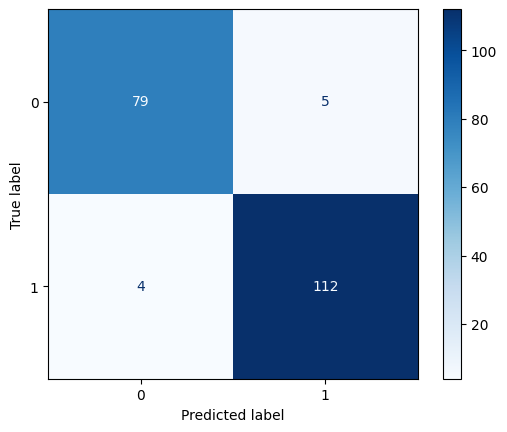

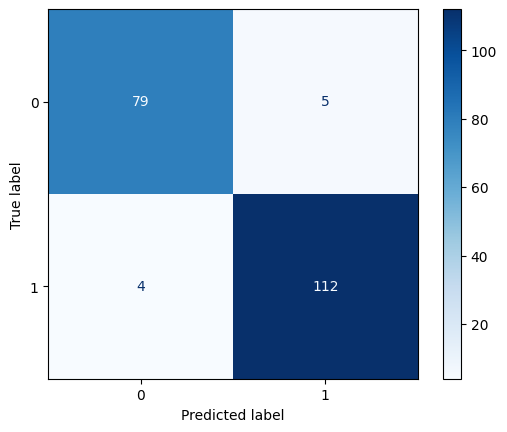

In [69]:
# Evalution

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

print(classification_report(y_test, rfc2_cv_pred))
print(confusion_matrix(y_test, rfc2_cv_pred))
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_auc_score, ConfusionMatrixDisplay
)

print(classification_report(y_test, rfc2_cv_pred))
print("Accuracy:", accuracy_score(y_test, rfc2_cv_pred))

best_model = rfc2_cv.best_estimator_
positive_class_index = list(best_model.classes_).index(1)
y_score = best_model.predict_proba(X_test_processed)[:, positive_class_index]
print("ROC-AUC:", roc_auc_score(y_test, y_score))

cm = confusion_matrix(y_test, rfc2_cv_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_model.classes_
)
disp.plot(cmap="Blues", values_format="d");
disp.plot(cmap="Blues", values_format="d");

## Deploy Model

In [70]:
# serialization
import joblib

#dump, load
joblib.dump(rfc, 'best_model_rfc_project.joblib')

['best_model_rfc_project.joblib']

In [71]:
best_rfc = joblib.load('best_model_rfc_project.joblib')

In [75]:
from sklearn.pipeline import Pipeline

# Menyimpan proses-proses
pipeline_rfc = Pipeline([
    ('preprocessing', ct), # preprocessing
    ('model', best_rfc) # pemodelan
])

In [86]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.1, random_state=42)

In [87]:
pipeline_rfc = Pipeline([
    ("preprocessing", ct),
    ("model", rfc2_cv.best_estimator_)
])

pipeline_rfc.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'days_active',
                                                   'courses_enrolled',
                                                   'courses_completed',
                                                   'quizzes_attempted',
                                                   'average_score',
                                                   'time_spent_minutes']),
                                                 ('cat', OneHotEncoder(),
                                                  ['gender', 'signup_method',
                                                   'device_type'])])),
                ('model', RandomForestClassifier(min_samples_leaf=5))])

In [88]:
# menyimpan pipeline
joblib.dump(pipeline_rfc, 'pipeline_rfc_project_joblib')

['pipeline_rfc_project_joblib']

In [82]:
def predict():
    data = {}

    for i in numeric: # inputan numeric
        data[i] = float(input(f'masukkan nilai {i}:')) # str to float

    for i in categorical: # inputan categorical
            data[i] = input(f'masukkan nilai {i}:')

    data = pd.DataFrame(data, index=[0]) 
    return pipeline_rfc.predict(data)

In [85]:
predict()

array([1], dtype=int64)

In [84]:
# sample data predict
X.loc[0]

age                      56.0
gender                   Male
signup_method          Google
device_type           Desktop
days_active                32
courses_enrolled            3
courses_completed           5
quizzes_attempted           9
average_score            72.0
time_spent_minutes       9115
Name: 0, dtype: object